In [1]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os
import math

sns.set_style("white")

# Grid order
METRICS_LIST = [
    'ndcg@5', 'ndcg@10', 'ndcg@50', 'ndcg@100',
    'unbiased_ndcg@5', 'unbiased_ndcg@10', 'unbiased_ndcg@50', 'unbiased_ndcg@100',
    # 'precision@5', 'precision@10', 'precision@50', 'precision@100',
    # 'unbiased_precision@5', 'unbiased_precision@10', 'unbiased_precision@50', 'unbiased_precision@100',
    # 'recall@5', 'recall@10', 'recall@50', 'recall@100',
    # 'unbiased_recall@5', 'unbiased_recall@10', 'unbiased_recall@50', 'unbiased_recall@100',
    # 'mean_mrr@5', 'mean_mrr@10', 'mean_mrr@50', 'mean_mrr@100',
    # 'mean_mrr', 'group_auc', 'dummy_spacer_1', 'dummy_spacer_2'
]

METRICS_LIST = ['ndcg@100']

COLOR_MAP = {
    "GT": "black",
    "Full": "tab:orange",
    "Exposed": "tab:blue",
    "Random@$e$": "tab:purple",
    "Random@$n$": "tab:brown",
    "Popularity@$n$": "tab:green",
    "Positivity@$n$": "tab:red",
    "Skew@$n$": "tab:pink",
    "WTD@$n$": "tab:gray",
    "WTDH@$n$": "tab:olive"
}

NUM_RUNS = 50

def unique(sequence):
    seen = set()
    return [x for x in sequence if not (x in seen or seen.add(x))]

# Support Functions

In [2]:
def extract_recname(c):
    try:
        return c[0:c.index("-test")].split(":")[1]
    except:
        return c

def load_data(dataset_path, bias_types):
    df_by_bias_type = {}
    # 1. Loading
    for bias_type in bias_types:
        results_file = dataset_path.format(bias_type)
        if os.path.exists(results_file):
            base_df = pd.read_parquet(results_file)
            if "rating" in base_df.columns:
                base_df["sum_rating"] = base_df["rating"].apply(sum)
            if "sum_rating" in base_df.columns:
                base_df = base_df.query("sum_rating > 0")
            if "pscore" in base_df.columns:
                base_df.drop(["pscore"], axis=1, inplace=True)

            # Discover all unique recs
            all_keys = base_df["result_key"].unique()
            all_recs = sorted(list(set([extract_recname(k) for k in all_keys if extract_recname(k) is not None])))

            run_id = 0
            list_df = []
            np.random.seed(42)
            seen_combinations = set()
            while len(seen_combinations) < NUM_RUNS:
                # Generate combination: vary how many and which models
                # run_id = 0 uses all recommenders
                num_recs_to_select = np.random.randint(2, len(all_recs) + 1) if run_id > 0 else len(all_recs)
                selected_recs = np.random.choice(all_recs, size=num_recs_to_select, replace=False)

                # Sort the selection and convert to a tuple so it can be hashed in a set
                combo_key = tuple(sorted(selected_recs))

                if combo_key in seen_combinations:
                    continue
                seen_combinations.add(combo_key)

                # Filter base dataframe for only the selected recs
                mask = base_df["result_key"].apply(lambda k: extract_recname(k) in selected_recs)

                df_run = base_df[mask].copy()
                df_run["run_id"] = np.int16(run_id)
                list_df.append(df_run)

                run_id += 1
            df_by_bias_type[bias_type] = pd.concat(list_df)
        else:
            print(f"File not found: {results_file}")

    # 2. Processing
    df_by_biastype_metric_biasmodel_sampler = {}
    bias_models = []

    for bias_type, base_df in df_by_bias_type.items():
        df_byline = base_df.pivot(index=["run_id", "userID"], columns="result_key", values="evaluation")

        samplers = sorted({c.split("_")[-1] for c in df_byline.columns})
        bias_models = sorted({c[c.index("test_")+5: c.rindex(":")] for c in df_byline.columns if "test_" in c and ":" in c})
        recs = sorted({extract_recname(c) for c in df_byline.columns if "-test" in c})

        df_by_biastype_metric_biasmodel_sampler[bias_type] = {}

        valid_metrics = [m for m in METRICS_LIST if not m.startswith("dummy")]

        for metric in valid_metrics:
            df_by_biastype_metric_biasmodel_sampler[bias_type][metric] = {}

            try:
                df_single_metric = df_byline.map(
                    lambda r: r.get(metric) if isinstance(r, dict) and metric in r else np.nan
                ).apply(pd.to_numeric, errors='coerce')
            except Exception as e:
                continue

            for bias in bias_models:
                for sampler in samplers:
                    rel_cols = [c for c in df_single_metric.columns if c.split("_")[-1] == sampler and f"test_{bias}" in c]
                    if not rel_cols: continue

                    df_temp = df_single_metric.loc[:, rel_cols].dropna()
                    if df_temp.empty: continue

                    df_temp.rename(lambda c: extract_recname(c), axis=1, inplace=True)

                    if df_temp.columns.duplicated().any():
                        df_temp = df_temp.loc[:, ~df_temp.columns.duplicated()]

                    valid_recs = [r for r in recs if r in df_temp.columns]
                    if not valid_recs: continue
                    df_temp = df_temp[valid_recs]

                    df_temp["biastype"] = bias_type
                    df_temp["metric"] = metric
                    df_temp["bias"] = bias
                    df_temp["sampler"] = sampler

                    df_by_biastype_metric_biasmodel_sampler[bias_type][metric].setdefault(bias, {})
                    df_by_biastype_metric_biasmodel_sampler[bias_type][metric][bias][sampler] = df_temp
    return df_by_bias_type, df_by_biastype_metric_biasmodel_sampler

In [3]:
def format_sampler_name(c, return_at=False):
    if not return_at:
        c = c.split("@")[0]
    c = c.split("-")[-1].replace("CNC", "").capitalize()
    if c.startswith("Random"): c = "Random@$n$"
    if c.startswith("Randexpo"): c = "Random@$e$"
    if c == "Gt": c = "GT"
    if c.startswith("Wtd"): c = c.upper() + "@$n$"
    if c.startswith("Pop"): c = "Popularity" + "@$n$"
    if c.startswith("Pos"): c = "Positivity" + "@$n$"
    if c.startswith("Skew"): c = "Skew" + "@$n$"
    if "@" in c and return_at:
        c = (c.split("@")[0] + "@" + c.split("@")[-1] if return_at else "")
    return c

def sort_legend(handle, labels):
    expected_order = {"GT": 0, "Full": 1, "Exposed": 2, "Random@$e$": 3, "Random@$n$": 4,
                      "Popularity@$n$": 5, "Positivity@$n$": 6, "Skew@$n$": 7, "WTD@$n$": 8, "WTDH@$n$": 9}
    sorted_indices = sorted(range(len(labels)), key=lambda i: expected_order.get(labels[i], len(expected_order)))
    return [handle[i] for i in sorted_indices], [labels[i] for i in sorted_indices]

def plot_metric_grid(plot_func, plot_name, bias_models, output_path=None):
    plt.rcParams.update({'font.size': 18})
    if len(bias_models) == 1:
        # --- Fixed grid setup ---
        cols = 4
        n_metrics = len(METRICS_LIST)
        rows = math.ceil(n_metrics / cols)

        fig, axes = plt.subplots(rows, cols, figsize=(24, 4 * rows))
        axes_flat = axes.flatten()

        handles, labels = None, None

        for idx, metric in enumerate(METRICS_LIST):
            ax = axes_flat[idx]

            if metric.startswith("dummy"):
                ax.set_visible(False)
                continue

            has_data = plot_func(ax, metric, bias_models[0])

            ax.set_xlabel("")
            ax.set_ylabel("")
            if idx / cols < (rows - 1):
                ax.set_xticklabels([])
                ax.xaxis.set_tick_params(length=0)
            if idx % cols != 0:
                ax.set_yticklabels([])
                ax.yaxis.set_tick_params(length=0)

            if has_data:
                clean_title = metric.replace("_", " ").title().replace("Ndcg", "nDCG")
                if "Unbiased" in clean_title:
                    clean_title = clean_title.replace("Unbiased ", "") + " (Unbiased)"
                ax.set_title(clean_title, fontsize=16, fontweight='bold')

                if not ax.get_xlabel(): ax.set_xlabel("")
                if not ax.get_ylabel(): ax.set_ylabel("")

                if handles is None and ax.get_legend():
                    h, l = ax.get_legend_handles_labels()
                    if h: handles, labels = h, l
                    ax.get_legend().remove()
                elif ax.get_legend():
                    ax.get_legend().remove()
            else:
                # Keep the space in the grid
                ax.set_visible(False)

        for idx in range(len(METRICS_LIST), len(axes_flat)):
            axes_flat[idx].set_visible(False)

        plt.tight_layout(rect=[0, 0.015, 1, 0.98], w_pad=0.5, h_pad=0.5)
        fig.text(0.5, 0.005, "Sample Size ($n$)", ha="center", fontsize=20)
        if handles and labels:
            sorted_h, sorted_l = sort_legend(handles, labels)
            fig.legend(sorted_h, sorted_l, loc='upper center', bbox_to_anchor=(0.5, 0.0),
                       ncol=min(len(handles), 10), frameon=False, fontsize=20)

        # plt.suptitle(f"{plot_name}", fontsize=22, y=1.002)
        plt.show()

        if output_path is not None:
            fig.savefig(
                output_path,
                dpi=1300,
                bbox_inches="tight",
                pad_inches=0.05
            )
    else:
        print("Multiple bias models detected. Plotting skipped.")

# Coat

## Loading Dataset

In [4]:
CURRENT_RESULT_PATH = "/mnt/dados02/" + os.environ['USER'] + "/sampling/data/coat/result/2026-02-26 00:00/2026-02-26 00:00_{}.parquet"

In [5]:
bias_types = ["coat"]
df_by_bias_type, df_by_biastype_metric_biasmodel_sampler = load_data(CURRENT_RESULT_PATH, bias_types)

## Research Questions

### Q1: Resolution (Tie Rate)

In [6]:
df_ties_all = {}

valid_metrics = [m for m in METRICS_LIST if not m.startswith("dummy")]
for metric in valid_metrics:
    list_ties_df = []
    for biastype in bias_types:
        if metric not in df_by_biastype_metric_biasmodel_sampler[biastype]: continue
        df_bias_data = df_by_biastype_metric_biasmodel_sampler[biastype][metric]

        for bias in df_bias_data:
            for sampler in df_bias_data[bias]:
                df_curr = df_bias_data[bias][sampler]

                score_cols = df_curr.select_dtypes("number").columns
                valid_models_count = df_curr[score_cols].notna().sum(axis=1)
                comps = valid_models_count * (valid_models_count - 1) / 2

                df_ranks = df_curr[score_cols].rank(
                    axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                )

                # Calculate ties per row
                counts = df_ranks.apply(pd.Series.value_counts, axis=1).fillna(0)
                ties = counts.apply(lambda x: sum(k * (k - 1) / 2 for k in x if k > 1), axis=1)

                # Calculate tie_rate per row (user) and handle zero combinations safely
                tie_rate_series = ties / comps
                tie_rate_series = tie_rate_series.fillna(0.0)

                # Average over users for EACH run_id to preserve variance for sns.lineplot
                temp_df = pd.DataFrame({"tie_rate": tie_rate_series})
                run_avg = temp_df.groupby(level="run_id")["tie_rate"].mean().reset_index()

                for _, row in run_avg.iterrows():
                    list_ties_df.append({
                        "run_id": row["run_id"],
                        "sampler": sampler,
                        "bias": bias,
                        "tie_rate": row["tie_rate"],
                        "metric": metric,
                        "biastype": biastype
                    })
    if list_ties_df:
        df_ties_all[metric] = pd.DataFrame(list_ties_df)

def plot_ties_single(ax, metric, bias):
    if metric not in df_ties_all: return False
    df = df_ties_all[metric].query("bias == @bias").copy()
    if df.empty: return False

    df["sampler_clean"] = df["sampler"].apply(lambda s: format_sampler_name(s))
    df["at"] = df["sampler"].apply(lambda s: int(s.split("@")[-1]) if "@" in s else -1)

    ats = [x for x in df["at"].unique() if x != -1]
    if not ats: ats = [0]

    df_no_at = df[df["at"] == -1]
    df_at = df[df["at"] != -1]

    expanded = []
    for val in ats:
        temp = df_no_at.copy()
        temp["at"] = val
        expanded.append(temp)

    df_final = pd.concat([df_at] + expanded) if expanded else df_at
    df_final = df_final.reset_index(drop=True) # Correção Index

    if df_final.empty: return False

    sns.lineplot(data=df_final, x="at", y="tie_rate", hue="sampler_clean", palette=COLOR_MAP, ax=ax, marker="o")
    ax.set_yscale("log")
    ax.set_ylim(0.001, 1.0)
    return True

Plotting Resolution (Tie Rate)...


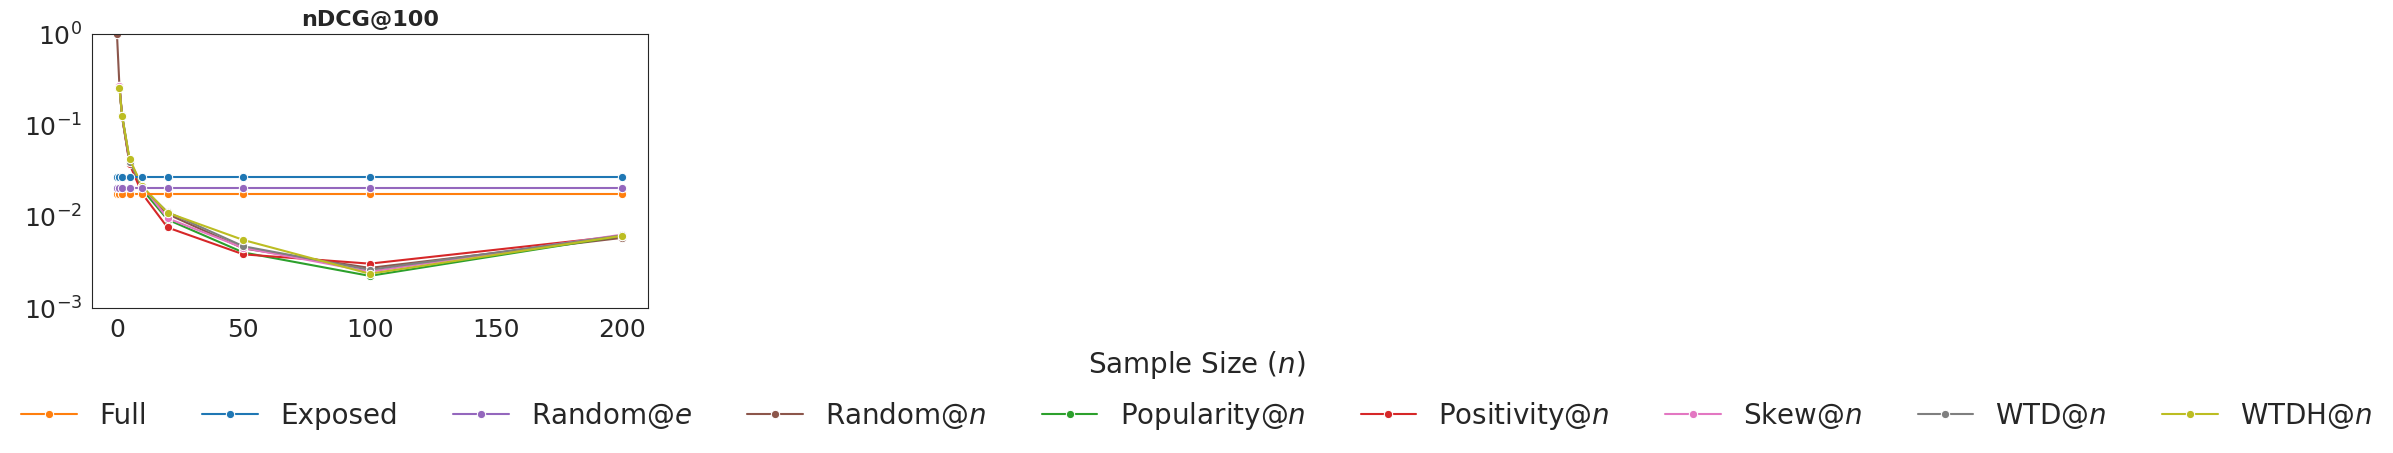

In [7]:
print("Plotting Resolution (Tie Rate)...")
plot_metric_grid(plot_ties_single, "", bias_types, "./q1_resolution_line_coat.pdf")

### Q2: Fidelity

In [8]:
def plot_kendall_local(ax, metric, bias):
    if metric not in df_by_biastype_metric_biasmodel_sampler["coat"]: return False
    data_block = df_by_biastype_metric_biasmodel_sampler["coat"][metric].get(bias)
    if not data_block: return False

    if "CNCFULL" not in data_block: return False

    df_gt_raw = data_block["CNCFULL"].loc[:, ~data_block["CNCFULL"].columns.duplicated()]
    df_gt_raw = df_gt_raw.apply(pd.to_numeric, errors='coerce')
    rank_gt = df_gt_raw.rank(axis=1, method="min", na_option="keep", ascending=False)

    results = []
    for sampler, df_samp_raw in data_block.items():
        # if sampler == "CNCFULL": continue

        df_samp = df_samp_raw.loc[:, ~df_samp_raw.columns.duplicated()]
        df_samp = df_samp.apply(pd.to_numeric, errors='coerce')

        common_idx = df_samp.index.intersection(rank_gt.index)
        if len(common_idx) == 0: continue

        r_samp = df_samp.loc[common_idx].rank(axis=1, method="min", na_option="keep", ascending=False)
        r_gt = rank_gt.loc[common_idx]

        # Calculate correlations per row, then group by run_id to get the mean per run
        corrs = r_samp.corrwith(r_gt, axis=1, method="kendall")
        corrs_per_run = corrs.groupby(level="run_id").mean()
        for run_id, val in corrs_per_run.items():
            results.append({
                "run_id": run_id,
                "sampler": sampler,
                "kendall": val
            })

    if not results: return False
    df_res = pd.DataFrame(results)

    df_res["sampler_clean"] = df_res["sampler"].apply(lambda s: format_sampler_name(s))
    df_res["at"] = df_res["sampler"].apply(lambda s: int(s.split("@")[-1]) if "@" in s else -1)

    ats = [x for x in df_res["at"].unique() if x != -1]
    if not ats: ats = [0]

    df_no_at = df_res[df_res["at"] == -1]
    df_at = df_res[df_res["at"] != -1]

    expanded = []
    for val in ats:
        temp = df_no_at.copy()
        temp["at"] = val
        expanded.append(temp)

    df_final = pd.concat([df_at] + expanded) if expanded else df_at
    df_final = df_final.reset_index(drop=True)

    if df_final.empty: return False

    sns.lineplot(data=df_final, x="at", y="kendall", hue="sampler_clean", ax=ax, marker="o")
    ax.set_ylim(-0.2, 1.05)
    return True

Plotting Fidelity: Position-Based Kendall Correlation (L)...


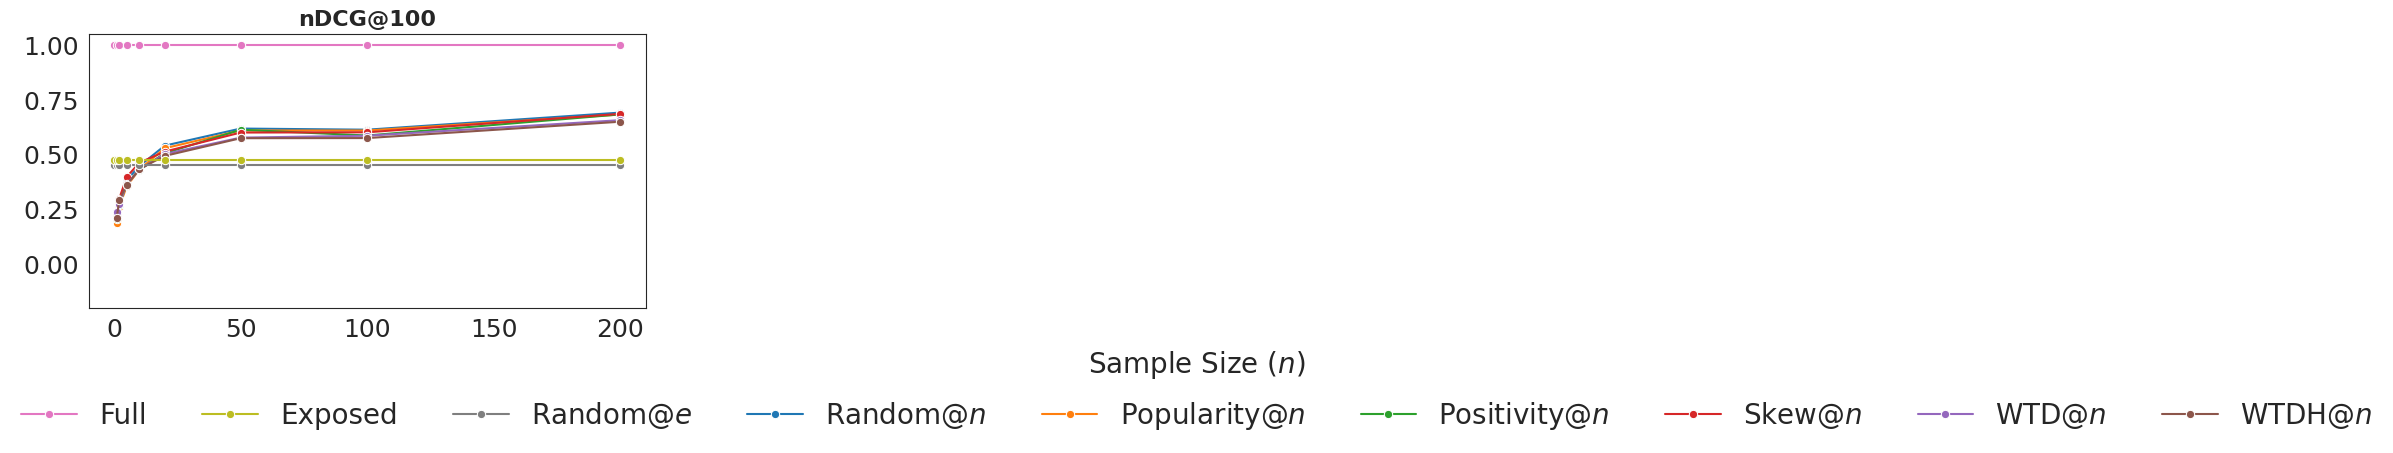

In [9]:
print("Plotting Fidelity: Position-Based Kendall Correlation (L)...")
plot_metric_grid(plot_kendall_local, "", bias_types, "./q2_fidelity_line_coat.pdf")

# R3

In [10]:
# Grid order
METRICS_LIST = ['ndcg@5', 'ndcg@10', 'ndcg@50', 'ndcg@100']

METRICS_LIST = ['ndcg@100']

## Loading Dataset

In [11]:
CURRENT_RESULT_PATH = "/mnt/dados02/" + os.environ['USER'] + "/sampling/data/r3/result/2026-02-26 00:00/2026-02-26 00:00_{}.parquet"

In [12]:
bias_types = ["r3"]
df_by_bias_type, df_by_biastype_metric_biasmodel_sampler = load_data(CURRENT_RESULT_PATH, bias_types)

## Research Questions

### Q1: Resolution (Tie Rate)

In [13]:
df_ties_all = {}

valid_metrics = [m for m in METRICS_LIST if not m.startswith("dummy")]
for metric in valid_metrics:
    list_ties_df = []
    for biastype in bias_types:
        if metric not in df_by_biastype_metric_biasmodel_sampler[biastype]: continue
        df_bias_data = df_by_biastype_metric_biasmodel_sampler[biastype][metric]

        for bias in df_bias_data:
            for sampler in df_bias_data[bias]:
                df_curr = df_bias_data[bias][sampler]

                score_cols = df_curr.select_dtypes("number").columns
                valid_models_count = df_curr[score_cols].notna().sum(axis=1)
                comps = valid_models_count * (valid_models_count - 1) / 2

                df_ranks = df_curr[score_cols].rank(
                    axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                )

                # Calculate ties per row
                counts = df_ranks.apply(pd.Series.value_counts, axis=1).fillna(0)
                ties = counts.apply(lambda x: sum(k * (k - 1) / 2 for k in x if k > 1), axis=1)

                # Calculate tie_rate per row (user) and handle zero combinations safely
                tie_rate_series = ties / comps
                tie_rate_series = tie_rate_series.fillna(0.0)

                # Average over users for EACH run_id to preserve variance for sns.lineplot
                temp_df = pd.DataFrame({"tie_rate": tie_rate_series})
                run_avg = temp_df.groupby(level="run_id")["tie_rate"].mean().reset_index()

                for _, row in run_avg.iterrows():
                    list_ties_df.append({
                        "run_id": row["run_id"],
                        "sampler": sampler,
                        "bias": bias,
                        "tie_rate": row["tie_rate"],
                        "metric": metric,
                        "biastype": biastype
                    })
    if list_ties_df:
        df_ties_all[metric] = pd.DataFrame(list_ties_df)

def plot_ties_single(ax, metric, bias):
    if metric not in df_ties_all: return False
    df = df_ties_all[metric].query("bias == @bias").copy()
    if df.empty: return False

    df["sampler_clean"] = df["sampler"].apply(lambda s: format_sampler_name(s))
    df["at"] = df["sampler"].apply(lambda s: int(s.split("@")[-1]) if "@" in s else -1)

    ats = [x for x in df["at"].unique() if x != -1]
    if not ats: ats = [0]

    df_no_at = df[df["at"] == -1]
    df_at = df[df["at"] != -1]

    expanded = []
    for val in ats:
        temp = df_no_at.copy()
        temp["at"] = val
        expanded.append(temp)

    df_final = pd.concat([df_at] + expanded) if expanded else df_at
    df_final = df_final.reset_index(drop=True) # Correção Index

    if df_final.empty: return False

    sns.lineplot(data=df_final, x="at", y="tie_rate", hue="sampler_clean", palette=COLOR_MAP, ax=ax, marker="o")
    ax.set_yscale("log")
    ax.set_ylim(0.001, 1.0)
    return True

Plotting Resolution (Tie Rate)...


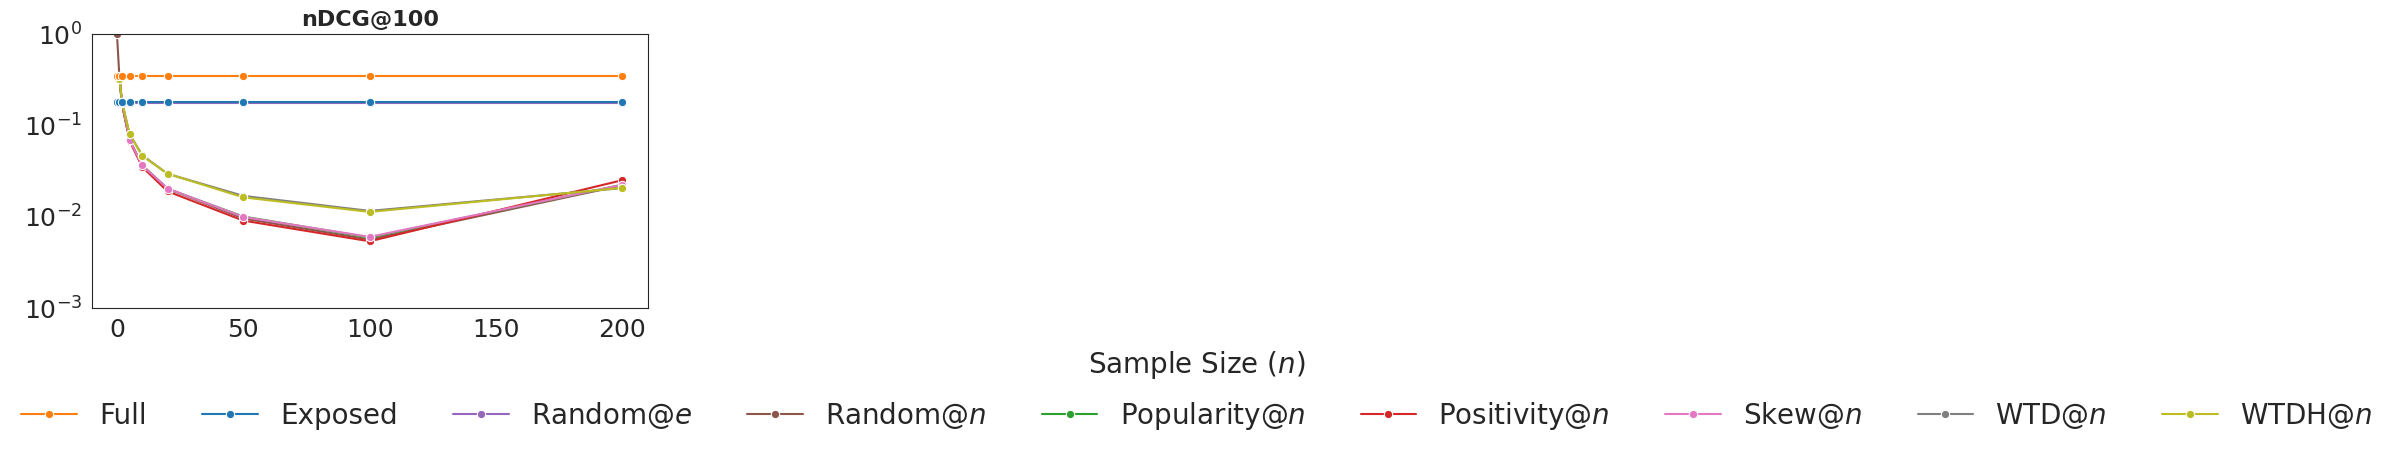

In [14]:
print("Plotting Resolution (Tie Rate)...")
plot_metric_grid(plot_ties_single, "", bias_types, "./q1_resolution_line_r3.pdf")

### Q2: Fidelity

In [15]:
def plot_kendall_local(ax, metric, bias):
    if metric not in df_by_biastype_metric_biasmodel_sampler["r3"]: return False
    data_block = df_by_biastype_metric_biasmodel_sampler["r3"][metric].get(bias)
    if not data_block: return False

    if "CNCFULL" not in data_block: return False

    df_gt_raw = data_block["CNCFULL"].loc[:, ~data_block["CNCFULL"].columns.duplicated()]
    df_gt_raw = df_gt_raw.apply(pd.to_numeric, errors='coerce')
    rank_gt = df_gt_raw.rank(axis=1, method="min", na_option="keep", ascending=False)

    results = []
    for sampler, df_samp_raw in data_block.items():
        # if sampler == "CNCFULL": continue

        df_samp = df_samp_raw.loc[:, ~df_samp_raw.columns.duplicated()]
        df_samp = df_samp.apply(pd.to_numeric, errors='coerce')

        common_idx = df_samp.index.intersection(rank_gt.index)
        if len(common_idx) == 0: continue

        r_samp = df_samp.loc[common_idx].rank(axis=1, method="min", na_option="keep", ascending=False)
        r_gt = rank_gt.loc[common_idx]

        # Calculate correlations per row, then group by run_id to get the mean per run
        corrs = r_samp.corrwith(r_gt, axis=1, method="kendall")
        corrs_per_run = corrs.groupby(level="run_id").mean()
        for run_id, val in corrs_per_run.items():
            results.append({
                "run_id": run_id,
                "sampler": sampler,
                "kendall": val
            })

    if not results: return False
    df_res = pd.DataFrame(results)

    df_res["sampler_clean"] = df_res["sampler"].apply(lambda s: format_sampler_name(s))
    df_res["at"] = df_res["sampler"].apply(lambda s: int(s.split("@")[-1]) if "@" in s else -1)

    ats = [x for x in df_res["at"].unique() if x != -1]
    if not ats: ats = [0]

    df_no_at = df_res[df_res["at"] == -1]
    df_at = df_res[df_res["at"] != -1]

    expanded = []
    for val in ats:
        temp = df_no_at.copy()
        temp["at"] = val
        expanded.append(temp)

    df_final = pd.concat([df_at] + expanded) if expanded else df_at
    df_final = df_final.reset_index(drop=True)

    if df_final.empty: return False

    sns.lineplot(data=df_final, x="at", y="kendall", hue="sampler_clean", ax=ax, marker="o")
    ax.set_ylim(-0.2, 1.05)
    return True

Plotting Fidelity: Position-Based Kendall Correlation (L)...


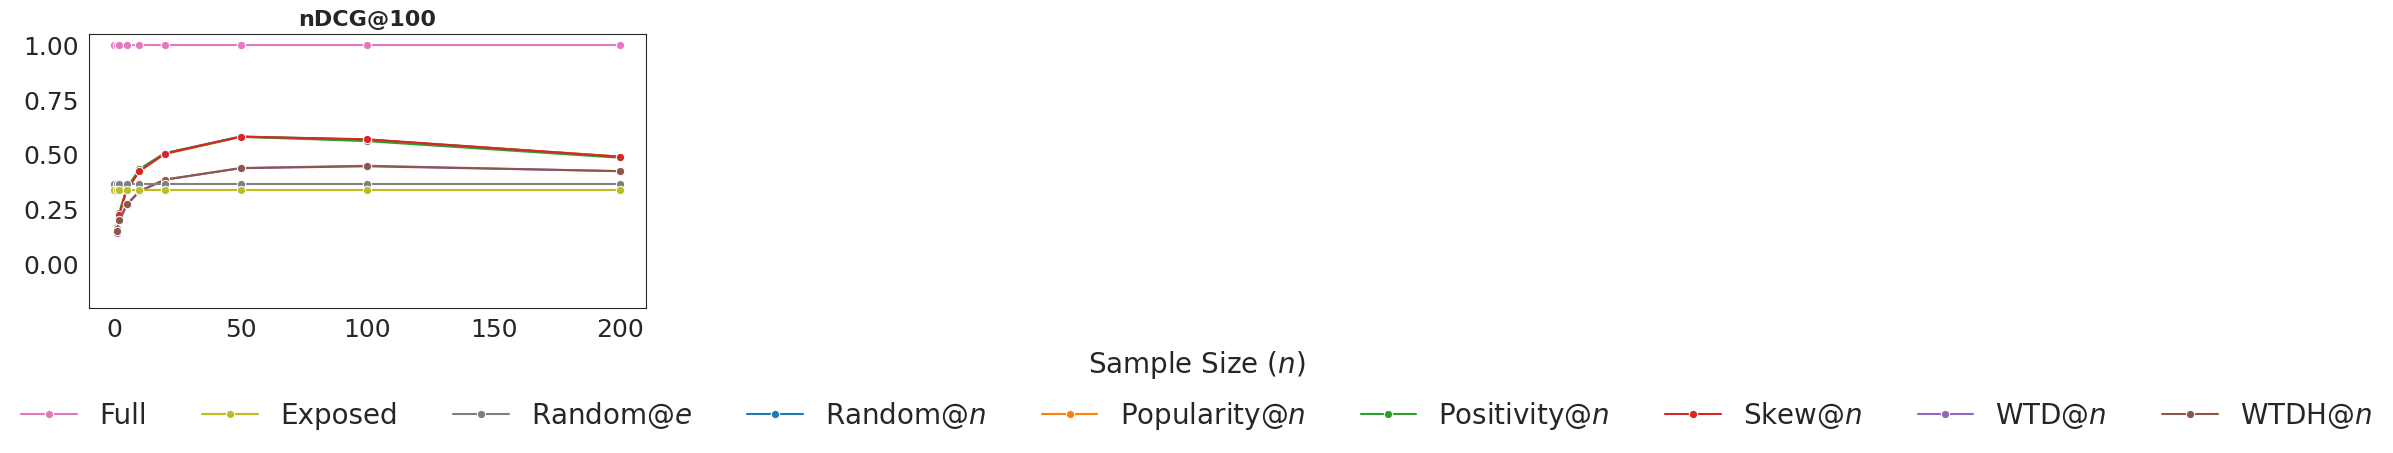

In [16]:
print("Plotting Fidelity: Position-Based Kendall Correlation (L)...")
plot_metric_grid(plot_kendall_local, "", bias_types, "./q2_fidelity_line_r3.pdf")